# Exploração inicial da BD5 — taxas de rendimento (INEP, 2011–2025)

Objetivo: entender como os dados se comportam antes de fechar o recorte do pôster.

**Como usar**
1. Deixe este notebook na mesma pasta do `bd5.zip` (pasta `Dados/`).
2. Ajuste a célula de **Configuração**, se precisar (etapa, corte de tamanho).
3. Rode de cima para baixo (*Run All*). A leitura da base leva alguns minutos.

**Roteiro**
1. Extração do `bd5.zip` e leitura
2. Visão geral da base
3. Checagens de consistência
4. Taxas por escola-ano e comparação entre etapas
5. Acumulado por escola (etapa escolhida)
6. Boxplots por grupo: região, rede, localização, combinações e UF
7. Sensibilidade: escola-ano × acumulado e corte por tamanho
8. Exportação dos resumos

Medidas de resumo: mediana e quartis, como sugerido pela professora. Outliers pelo critério de Tukey: abaixo de Q1 − 1,5·AIQ ou acima de Q3 + 1,5·AIQ.

In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Configuração

Os nomes das colunas seguem o `dicionario_dados_educaionais_2011a2025.xlsx`. Se a BD5 tiver nomes diferentes, a célula de leitura avisa quais faltam.

In [2]:
# Arquivos
ARQUIVO_ZIP = Path("bd5.zip")
PASTA_EXTRAIDA = Path("bd5")             # para onde o zip é extraído
PASTA_SAIDA = Path("saida_exploracao")   # figuras e tabelas
SALVAR_FIGURAS = True

# Recorte
ETAPA = "EM"      # "AI", "AF" ou "EM"
MIN_MAT = 30      # corte de tamanho: média anual de matrículas na etapa

# Colunas (dicionário de dados)
COL_ANO, COL_ESCOLA = "ANO", "CO_ESCOLA"
COL_REGIAO, COL_UF = "REGIAO", "UF"
COL_LOC, COL_DEP = "LOCALIZACAO", "DEP_ADM"
COLS_ID = [COL_ANO, COL_ESCOLA, "NO_ESCOLA", "CO_MUNICIPIO", "NO_MUNICIPIO",
           COL_UF, COL_REGIAO, COL_LOC, COL_DEP]

ETAPAS = {
    "AI": {"mat": ["QT_MAT_AI_REG", "QT_MAT_AI_INT"],
           "apr": "QT_APR_AI_TOTAL", "rep": "QT_REP_AI_TOTAL", "abn": "QT_ABN_AI_TOTAL"},
    "AF": {"mat": ["QT_MAT_AF_REG", "QT_MAT_AF_INT"],
           "apr": "QT_APR_AF_TOTAL", "rep": "QT_REP_AF_TOTAL", "abn": "QT_ABN_AF_TOTAL"},
    "EM": {"mat": ["QT_MAT_EM_REG", "QT_MAT_EM_INT"],
           "apr": "QT_APR_EM_TOTAL", "rep": "QT_REP_EM_TOTAL", "abn": "QT_ABN_EM_TOTAL"},
}
NOME_ETAPA = {"AI": "Anos Iniciais", "AF": "Anos Finais", "EM": "Ensino Médio"}
TAXAS = ["apr", "rep", "abn"]
NOME_TAXA = {"apr": "Aprovação", "rep": "Reprovação", "abn": "Abandono"}

ORDEM_REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
ORDEM_DEP = ["Federal", "Estadual", "Municipal", "Privada"]
ORDEM_LOC = ["Urbana", "Rural"]
ORDEM_GRUPO = ["Pública urbana", "Pública rural", "Privada urbana", "Privada rural"]

COLS_QT = [c for cfg in ETAPAS.values() for c in cfg["mat"] + [cfg[t] for t in TAXAS]]
COLS_PRED = ["ENS_PRED_AI", "ENS_PRED_AF", "ENS_PRED_EM"]
(PASTA_SAIDA / "figuras").mkdir(parents=True, exist_ok=True)

## 1. Extração e leitura

O zip é extraído uma vez para a pasta `bd5/`. Nas próximas execuções, a extração é pulada.

> O CSV extraído é grande. Vale incluir `Dados/bd5/` no `.gitignore` para não subi-lo ao GitHub.

In [3]:
with zipfile.ZipFile(ARQUIVO_ZIP) as z:
    print("Conteúdo do zip:")
    for info in z.infolist():
        if not info.is_dir():
            print(f"  {info.filename:60s} {info.file_size / 1e6:8.1f} MB")
    if PASTA_EXTRAIDA.exists():
        print("\nPasta já extraída — extração pulada.")
    else:
        z.extractall(PASTA_EXTRAIDA)
        print(f"\nExtraído em {PASTA_EXTRAIDA}/")

csvs = sorted(p for p in PASTA_EXTRAIDA.rglob("*.csv") if "__MACOSX" not in p.parts)
assert csvs, "Nenhum CSV encontrado dentro do zip."
if len(csvs) > 1:
    print("Mais de um CSV no zip; usando o primeiro:", [str(p) for p in csvs])
ARQUIVO_CSV = csvs[0]
print("Arquivo de dados:", ARQUIVO_CSV)

Conteúdo do zip:
  bd5.csv                                                         280.8 MB

Extraído em bd5/
Arquivo de dados: bd5\bd5.csv


In [4]:
def ler_csv(caminho):
    """Tenta ; e , como separador e utf-8 / latin-1 como encoding."""
    for enc in ["utf-8-sig", "latin-1"]:
        for sep in [";", ","]:
            try:
                df = pd.read_csv(caminho, sep=sep, encoding=enc, low_memory=False)
            except UnicodeDecodeError:
                break
            if df.shape[1] > 1:
                print(f"Lido com sep='{sep}', encoding='{enc}'")
                return df
    raise ValueError("Não foi possível ler o CSV.")


df = ler_csv(ARQUIVO_CSV)
df.columns = df.columns.str.strip()

faltando = [c for c in COLS_ID + COLS_QT if c not in df.columns]
extras = [c for c in df.columns if c not in COLS_ID + COLS_QT + COLS_PRED]
print(f"{df.shape[0]:,} linhas × {df.shape[1]} colunas".replace(",", "."))
print("Colunas esperadas que faltam:", faltando or "nenhuma")
print("Colunas além do dicionário:", extras or "nenhuma")
assert not faltando, "Ajuste os nomes na célula de Configuração."

df[COLS_QT] = df[COLS_QT].apply(pd.to_numeric, errors="coerce")
df.head()

Lido com sep=';', encoding='utf-8-sig'
2.051.631 linhas × 27 colunas
Colunas esperadas que faltam: nenhuma
Colunas além do dicionário: nenhuma


,ANO,CO_ESCOLA,NO_ESCOLA,CO_MUNICIPIO,NO_MUNICIPIO,UF,REGIAO,LOCALIZACAO,DEP_ADM,QT_MAT_AI_REG,QT_MAT_AI_INT,QT_APR_AI_TOTAL,QT_REP_AI_TOTAL,QT_ABN_AI_TOTAL,QT_MAT_AF_REG,QT_MAT_AF_INT,QT_APR_AF_TOTAL,QT_REP_AF_TOTAL,QT_ABN_AF_TOTAL,QT_MAT_EM_REG,QT_MAT_EM_INT,QT_APR_EM_TOTAL,QT_REP_EM_TOTAL,QT_ABN_EM_TOTAL,ENS_PRED_AI,ENS_PRED_AF,ENS_PRED_EM
0,2011,53000846,CEF 01 DE BRASILIA,5300108,Brasília,DF,Centro-Oeste,Urbana,Estadual,0,0,NaN,NaN,NaN,451,5,412.0,30.0,14.0,0,0,NaN,NaN,NaN,NaN,Regular,NaN
1,2011,53000854,CEF 01 DO PLANALTO,5300108,Brasília,DF,Centro-Oeste,Urbana,Estadual,318,0,269.0,41.0,7.0,226,0,207.0,16.0,3.0,0,0,NaN,NaN,NaN,Regular,Regular,NaN
2,2011,53000862,CEF 02 DE BRASILIA,5300108,Brasília,DF,Centro-Oeste,Urbana,Estadual,0,0,NaN,NaN,NaN,231,1,190.0,41.0,1.0,0,0,NaN,NaN,NaN,NaN,Regular,NaN
3,2011,53000870,CEF 03 DE BRASILIA,5300108,Brasília,DF,Centro-Oeste,Urbana,Estadual,0,0,NaN,NaN,NaN,496,2,460.0,36.0,2.0,0,0,NaN,NaN,NaN,NaN,Regular,NaN
4,2011,53000889,CEF 04 DE BRASILIA,5300108,Brasília,DF,Centro-Oeste,Urbana,Estadual,0,0,NaN,NaN,NaN,474,0,434.0,39.0,1.0,0,0,NaN,NaN,NaN,NaN,Regular,NaN


## 2. Visão geral da base

In [5]:
df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2051631 entries, 0 to 2051630
Data columns (total 27 columns):
 #   Column           Dtype  
---  ------           -----  
 0   ANO              int64  
 1   CO_ESCOLA        int64  
 2   NO_ESCOLA        object 
 3   CO_MUNICIPIO     int64  
 4   NO_MUNICIPIO     object 
 5   UF               object 
 6   REGIAO           object 
 7   LOCALIZACAO      object 
 8   DEP_ADM          object 
 9   QT_MAT_AI_REG    int64  
 10  QT_MAT_AI_INT    int64  
 11  QT_APR_AI_TOTAL  float64
 12  QT_REP_AI_TOTAL  float64
 13  QT_ABN_AI_TOTAL  float64
 14  QT_MAT_AF_REG    int64  
 15  QT_MAT_AF_INT    int64  
 16  QT_APR_AF_TOTAL  float64
 17  QT_REP_AF_TOTAL  float64
 18  QT_ABN_AF_TOTAL  float64
 19  QT_MAT_EM_REG    int64  
 20  QT_MAT_EM_INT    int64  
 21  QT_APR_EM_TOTAL  float64
 22  QT_REP_EM_TOTAL  float64
 23  QT_ABN_EM_TOTAL  float64
 24  ENS_PRED_AI      object 
 25  ENS_PRED_AF      object 
 26  ENS_PRED_EM      object 
dtypes: float64(9

In [6]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(1),
})
nulos

,nulos,% nulos
ANO,0,0.0
CO_ESCOLA,0,0.0
NO_ESCOLA,0,0.0
CO_MUNICIPIO,0,0.0
NO_MUNICIPIO,0,0.0
UF,0,0.0
REGIAO,0,0.0
LOCALIZACAO,0,0.0
DEP_ADM,0,0.0
QT_MAT_AI_REG,0,0.0


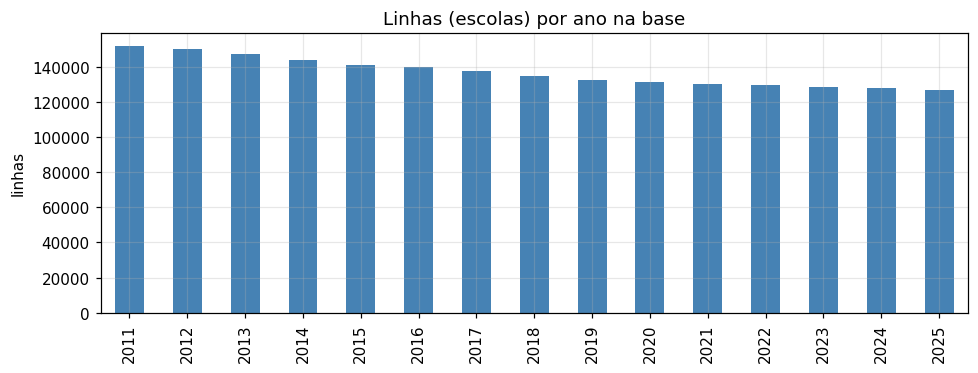

ANO,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
linhas,151509,150305,147185,143958,140864,139813,137296,134454,132456,131229,130127,129304,128364,128096,126671


In [7]:
por_ano = df.groupby(COL_ANO).size()

fig, ax = plt.subplots(figsize=(9, 3.5))
por_ano.plot.bar(ax=ax, color="steelblue")
ax.set_title("Linhas (escolas) por ano na base")
ax.set_xlabel("")
ax.set_ylabel("linhas")
plt.tight_layout()
plt.show()
por_ano.to_frame("linhas").T

In [8]:
for col in [COL_REGIAO, COL_LOC, COL_DEP]:
    contagem = df[col].value_counts(dropna=False)
    print(f"\n{col}")
    print(pd.DataFrame({"linhas": contagem,
                        "%": (contagem / len(df) * 100).round(1)}).to_string())


REGIAO
              linhas     %
REGIAO                    
Nordeste      838614  40.9
Sudeste       561679  27.4
Norte         303318  14.8
Sul           233667  11.4
Centro-Oeste  114353   5.6

LOCALIZACAO
              linhas     %
LOCALIZACAO               
Urbana       1218170  59.4
Rural         833461  40.6

DEP_ADM
            linhas     %
DEP_ADM                 
Municipal  1252756  61.1
Estadual    433425  21.1
Privada     357424  17.4
Federal       8026   0.4


In [9]:
df[COLS_QT].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T.round(1)

,count,mean,std,min,25%,50%,75%,99%,max
QT_MAT_AI_REG,2051631.0,97.2,143.9,0.0,7.0,37.0,128.0,657.0,2961.0
QT_MAT_AI_INT,2051631.0,13.5,46.8,0.0,0.0,0.0,0.0,240.0,1223.0
QT_APR_AI_TOTAL,1675842.0,127.7,152.2,0.0,23.0,70.0,177.0,693.0,2961.0
QT_REP_AI_TOTAL,1675842.0,5.9,12.7,0.0,0.0,1.0,6.0,62.0,481.0
QT_ABN_AI_TOTAL,1675842.0,1.1,3.9,0.0,0.0,0.0,1.0,17.0,950.0
QT_MAT_AF_REG,2051631.0,79.9,154.6,0.0,0.0,0.0,93.0,707.0,2706.0
QT_MAT_AF_INT,2051631.0,10.0,46.1,0.0,0.0,0.0,0.0,242.0,1391.0
QT_APR_AF_TOTAL,923995.0,178.9,172.9,0.0,55.0,120.0,253.0,786.0,2553.0
QT_REP_AF_TOTAL,923995.0,15.3,30.4,0.0,0.0,3.0,16.0,147.0,1598.0
QT_ABN_AF_TOTAL,923995.0,4.9,13.3,0.0,0.0,0.0,4.0,59.0,1068.0


## 3. Checagens de consistência

- duplicatas de (`ANO`, `CO_ESCOLA`);
- valores negativos;
- aprovação + reprovação + abandono comparados à matrícula total da etapa. Como as quantidades foram estimadas a partir das taxas e arredondadas, diferenças de 1 ou 2 alunos são esperadas;
- matrícula zero com rendimento informado, e matrícula positiva sem rendimento.

In [10]:
dup = df.duplicated([COL_ANO, COL_ESCOLA]).sum()
neg = (df[COLS_QT] < 0).sum()
print("Duplicatas (ANO, CO_ESCOLA):", dup)
print("Colunas com valores negativos:", neg[neg > 0].to_dict() or "nenhuma")

Duplicatas (ANO, CO_ESCOLA): 0
Colunas com valores negativos: nenhuma


In [11]:
linhas = []
for etapa, cfg in ETAPAS.items():
    mat = df[cfg["mat"]].sum(axis=1, min_count=1)
    soma = df[[cfg[t] for t in TAXAS]].sum(axis=1, min_count=1)
    tem_mat = mat > 0
    tem_rend = df[[cfg[t] for t in TAXAS]].notna().any(axis=1)
    diff = (soma - mat)[tem_mat & tem_rend]
    linhas.append({
        "etapa": etapa,
        "linhas com matrícula > 0": int(tem_mat.sum()),
        "com rendimento informado": int((tem_mat & tem_rend).sum()),
        "matrícula > 0 sem rendimento": int((tem_mat & ~tem_rend).sum()),
        "matrícula 0/vazia com alunos no rendimento": int((~tem_mat & (soma > 0)).sum()),
        "|soma − matrícula| ≤ 2 (%)": round((diff.abs() <= 2).mean() * 100, 1),
        "|soma − matrícula| > 10 (%)": round((diff.abs() > 10).mean() * 100, 2),
    })
pd.DataFrame(linhas).set_index("etapa")

,linhas com matrícula > 0,com rendimento informado,matrícula > 0 sem rendimento,matrícula 0/vazia com alunos no rendimento,|soma − matrícula| ≤ 2 (%),|soma − matrícula| > 10 (%)
etapa,,,,,,
AI,1694587,1675842,18745,0,100.0,0.0
AF,931442,923995,7447,0,100.0,0.0
EM,429002,426129,2873,0,100.0,0.0


## 4. Taxas por escola-ano e comparação entre etapas

Cada linha passa a ser uma escola-ano com matrícula positiva na etapa. A taxa é quantidade ÷ matrícula da etapa × 100.

A matrícula só entra no denominador onde a quantidade existe. Assim, um ano sem informação não dilui a taxa.

In [12]:
def montar_etapa(df, etapa):
    cfg = ETAPAS[etapa]
    e = df[[COL_ANO, COL_ESCOLA, COL_REGIAO, COL_UF, COL_LOC, COL_DEP]].copy()
    e["mat"] = df[cfg["mat"]].sum(axis=1, min_count=1)
    for t in TAXAS:
        e[t] = df[cfg[t]]
        e[f"mat_{t}"] = e["mat"].where(e[t].notna())
    e = e[(e["mat"] > 0) & e[TAXAS].notna().any(axis=1)].copy()

    privada = e[COL_DEP].astype(str).str.lower().str.contains("privad")
    e["rede"] = np.where(privada, "Privada", "Pública")
    e["grupo"] = e["rede"] + " " + e[COL_LOC].astype(str).str.strip().str.lower()
    for t in TAXAS:
        e[f"tx_{t}"] = e[t] / e[f"mat_{t}"] * 100
    e["etapa"] = etapa
    return e


dados = {et: montar_etapa(df, et) for et in ETAPAS}
{et: len(e) for et, e in dados.items()}

{'AI': 1675842, 'AF': 923995, 'EM': 426129}

In [13]:
painel = []
for etapa, e in dados.items():
    for t in TAXAS:
        x = e[f"tx_{t}"].dropna()
        painel.append({"etapa": etapa, "taxa": NOME_TAXA[t], "n": len(x),
                       "Q1": x.quantile(.25), "mediana": x.median(), "Q3": x.quantile(.75),
                       "% zero": (x == 0).mean() * 100, "% acima de 100": (x > 100).mean() * 100})
pd.DataFrame(painel).set_index(["etapa", "taxa"]).round(2)

n     Q1  mediana      Q3  % zero  % acima de 100
etapa taxa                                                               
AI    Aprovação   1675842  90.91    97.88  100.00    0.07             0.0
      Reprovação  1675842   0.00     1.23    7.32   43.43             0.0
      Abandono    1675842   0.00     0.00    0.45   72.17             0.0
AF    Aprovação    923995  85.71    95.28  100.00    0.20             0.0
      Reprovação   923995   0.00     2.86   10.11   34.79             0.0
      Abandono     923995   0.00     0.00    2.86   53.42             0.0
EM    Aprovação    426129  82.09    92.45   98.12    0.06             0.0
      Reprovação   426129   0.49     4.10   10.27   23.23             0.0
      Abandono     426129   0.00     1.16    6.76   40.90             0.0

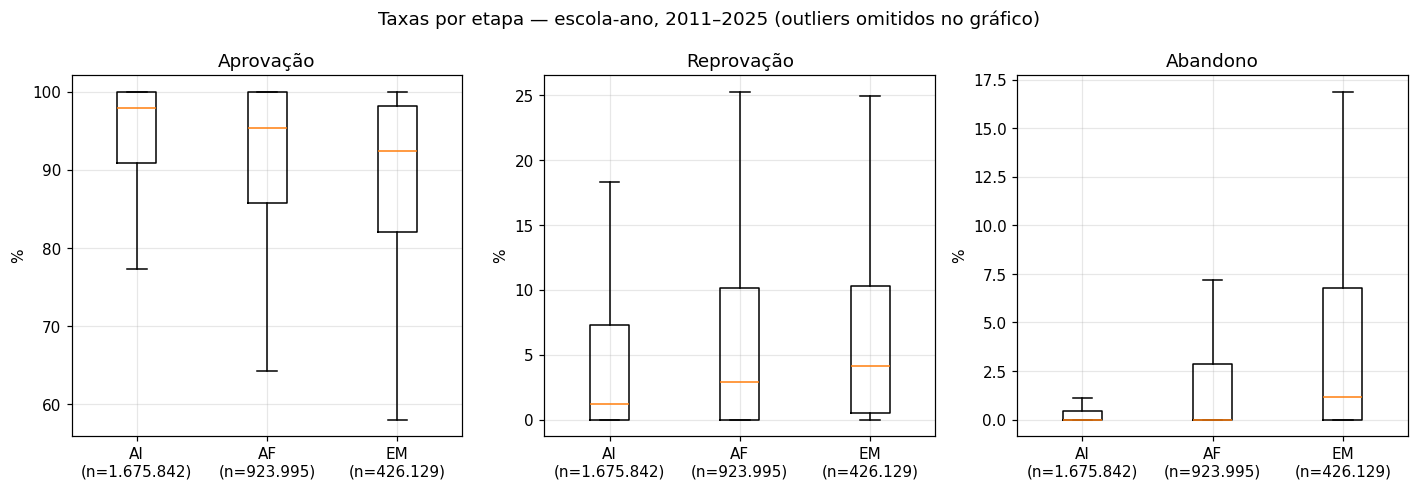

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, t in zip(axes, TAXAS):
    series = [dados[et][f"tx_{t}"].dropna() for et in ETAPAS]
    ax.boxplot(series, showfliers=False)
    ax.set_xticks(range(1, 4))
    ax.set_xticklabels([f"{et}\n(n={len(s):,})".replace(",", ".") for et, s in zip(ETAPAS, series)])
    ax.set_title(NOME_TAXA[t])
    ax.set_ylabel("%")
fig.suptitle("Taxas por etapa — escola-ano, 2011–2025 (outliers omitidos no gráfico)")
plt.tight_layout()
if SALVAR_FIGURAS:
    fig.savefig(PASTA_SAIDA / "figuras" / "00_comparacao_etapas.png", dpi=150)
plt.show()

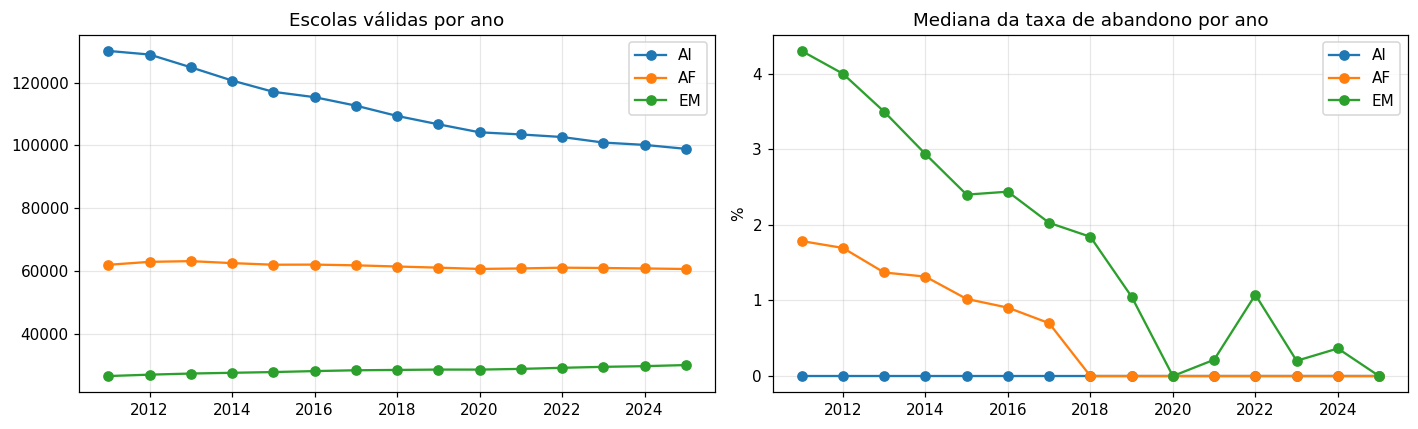

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for et, e in dados.items():
    e.groupby(COL_ANO).size().plot(ax=axes[0], marker="o", label=et)
    e.groupby(COL_ANO)["tx_abn"].median().plot(ax=axes[1], marker="o", label=et)
axes[0].set_title("Escolas válidas por ano")
axes[1].set_title("Mediana da taxa de abandono por ano")
axes[1].set_ylabel("%")
for ax in axes:
    ax.set_xlabel("")
    ax.legend()
plt.tight_layout()
plt.show()

**Antes de seguir:** com base nas tabelas e gráficos acima, confirme a etapa na célula de Configuração (`ETAPA`).

O gráfico por ano serve só para detectar anos anômalos na base, como 2020–2021 ou 2025. A análise do pôster é acumulada no período.

## 5. Acumulado por escola (etapa escolhida)

Cada escola vira um ponto. A taxa acumulada é a soma das quantidades em 2011–2025 dividida pela soma das matrículas. Para rede, localização, região e UF, vale a classificação do ano mais recente da escola.

In [16]:
def acumular(e):
    e = e.sort_values(COL_ANO)
    g = e.groupby(COL_ESCOLA)
    acc = g[["mat"] + TAXAS + [f"mat_{t}" for t in TAXAS]].sum(min_count=1)
    acc["n_anos"] = g[COL_ANO].nunique()
    acc = acc.join(g[[COL_REGIAO, COL_UF, COL_LOC, COL_DEP, "rede", "grupo"]].last())
    acc["mudou_classificacao"] = g[[COL_DEP, COL_LOC]].nunique().gt(1).any(axis=1)
    acc["mat_media_anual"] = acc["mat"] / acc["n_anos"]
    for t in TAXAS:
        acc[f"tx_{t}"] = acc[t] / acc[f"mat_{t}"] * 100
    return acc.reset_index()


esc_ano = dados[ETAPA]
acc = acumular(esc_ano)
print(f"{NOME_ETAPA[ETAPA]}: {len(acc):,} escolas".replace(",", "."))
print("Mudaram de rede ou localização no período:", int(acc["mudou_classificacao"].sum()))
print(f"Com média anual ≥ {MIN_MAT} matrículas:", int((acc["mat_media_anual"] >= MIN_MAT).sum()))

Ensino Médio: 36.851 escolas
Mudaram de rede ou localização no período: 521
Com média anual ≥ 30 matrículas: 33345


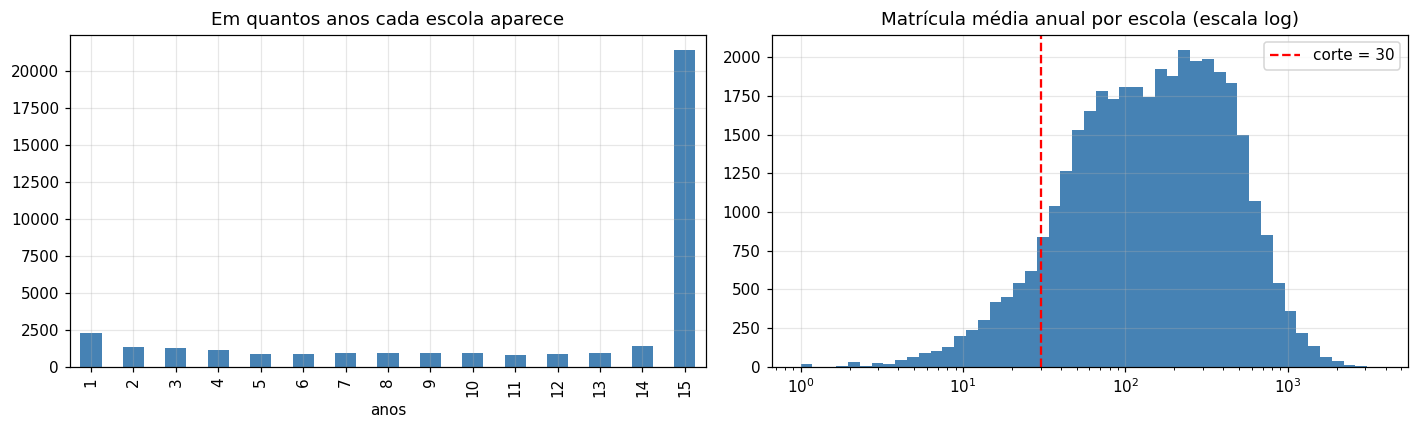

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
acc["n_anos"].value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Em quantos anos cada escola aparece")
axes[0].set_xlabel("anos")
axes[1].hist(acc["mat_media_anual"], bins=np.logspace(0, np.log10(acc["mat_media_anual"].max() + 1), 50),
             color="steelblue")
axes[1].set_xscale("log")
axes[1].axvline(MIN_MAT, color="red", ls="--", label=f"corte = {MIN_MAT}")
axes[1].set_title("Matrícula média anual por escola (escala log)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Boxplots por grupo

Cada figura mostra as três taxas. Abaixo de cada caixa vai o número de escolas do grupo. A tabela que segue traz os números da caixa: Q1, mediana, Q3, % de zeros e % de outliers.

In [18]:
def ordenar(grupos_presentes, ordem):
    base = [g for g in (ordem or sorted(grupos_presentes)) if g in grupos_presentes]
    return base + sorted(set(grupos_presentes) - set(base))


def boxplot_por(dados, col, titulo, arquivo=None, ordem=None, fliers=True, largura=14):
    grupos = ordenar(set(dados[col].dropna()), ordem)
    fig, axes = plt.subplots(1, 3, figsize=(largura, 5))
    for ax, t in zip(axes, TAXAS):
        pares = [(g, dados.loc[dados[col] == g, f"tx_{t}"].dropna()) for g in grupos]
        pares = [(g, s) for g, s in pares if len(s) > 0]
        ax.boxplot([s for _, s in pares], showfliers=fliers,
                   flierprops={"markersize": 1.5, "alpha": 0.3})
        ax.set_xticks(range(1, len(pares) + 1))
        ax.set_xticklabels([f"{g}\n(n={len(s):,})".replace(",", ".") for g, s in pares],
                           rotation=45 if len(pares) > 4 else 0,
                           ha="right" if len(pares) > 4 else "center", fontsize=8)
        ax.set_title(NOME_TAXA[t])
        ax.set_ylabel("%")
    fig.suptitle(titulo + ("" if fliers else "  (outliers omitidos no gráfico)"))
    plt.tight_layout()
    if SALVAR_FIGURAS and arquivo:
        fig.savefig(PASTA_SAIDA / "figuras" / arquivo, dpi=150)
    plt.show()


def resumo_por(dados, col, ordem=None):
    linhas = []
    for g in ordenar(set(dados[col].dropna()), ordem):
        sub = dados[dados[col] == g]
        for t in TAXAS:
            x = sub[f"tx_{t}"].dropna()
            if x.empty:
                continue
            q1, med, q3 = x.quantile([.25, .5, .75])
            aiq = q3 - q1
            linhas.append({col: g, "taxa": NOME_TAXA[t], "n": len(x),
                           "Q1": q1, "mediana": med, "Q3": q3,
                           "% zero": (x == 0).mean() * 100,
                           "% outliers": ((x < q1 - 1.5 * aiq) | (x > q3 + 1.5 * aiq)).mean() * 100})
    return pd.DataFrame(linhas).set_index([col, "taxa"]).round(2)


resumos = {}   # guarda as tabelas para exportar no final

### 6.1 Por região

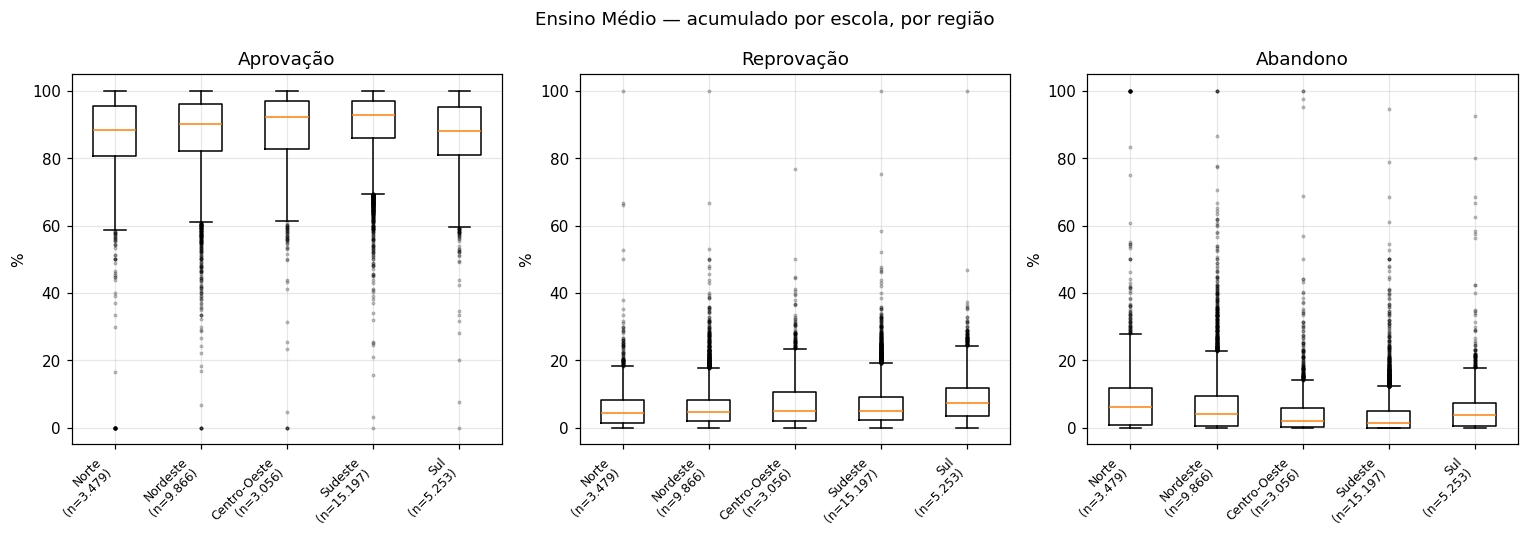

n     Q1  mediana     Q3  % zero  % outliers
REGIAO       taxa                                                        
Norte        Aprovação    3479  80.70    88.28  95.56    0.52        1.64
             Reprovação   3479   1.33     4.21   8.12   13.16        2.44
             Abandono     3479   0.81     6.00  11.66   12.50        2.39
Nordeste     Aprovação    9866  82.08    90.13  96.13    0.05        2.04
             Reprovação   9866   2.05     4.72   8.33   10.64        3.59
             Abandono     9866   0.43     4.09   9.38   13.10        3.22
Centro-Oeste Aprovação    3056  82.81    92.30  97.06    0.13        1.57
             Reprovação   3056   2.08     4.99  10.65    8.34        2.59
             Abandono     3056   0.12     1.83   5.73   20.19        4.97
Sudeste      Aprovação   15197  86.08    92.90  97.17    0.01        2.43
             Reprovação  15197   2.21     4.83   9.00    6.07        3.06
             Abandono    15197   0.00     1.35   4.93   25.85        3.38
Sul          Aprovação    5253  80.92    88.14  95.25    0.02        0.88
             Reprovação   5253   3.49     7.17  11.84    4.02        1.66
             Abandono     5253   0.35     3.77   7.35   13.12        1.60

In [19]:
boxplot_por(acc, COL_REGIAO, f"{NOME_ETAPA[ETAPA]} — acumulado por escola, por região",
            f"{ETAPA}_acumulado_regiao.png", ordem=ORDEM_REGIOES, largura=14)
resumos["regiao"] = resumo_por(acc, COL_REGIAO, ordem=ORDEM_REGIOES)
resumos["regiao"]

### 6.2 Por dependência administrativa

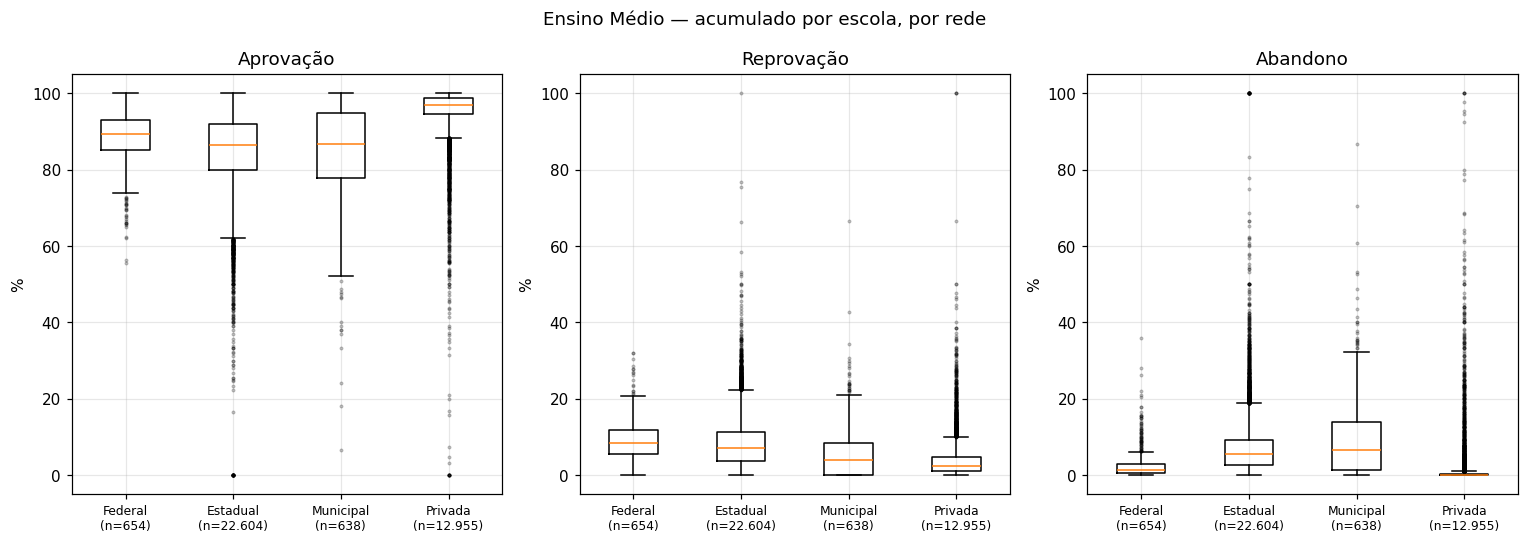

n     Q1  mediana     Q3  % zero  % outliers
DEP_ADM   taxa                                                        
Federal   Aprovação     654  85.02    89.42  92.98    0.00        4.59
          Reprovação    654   5.68     8.41  11.83    1.68        2.45
          Abandono      654   0.57     1.30   2.82    4.28       10.70
Estadual  Aprovação   22604  79.95    86.37  91.94    0.09        1.73
          Reprovação  22604   3.81     7.04  11.25    4.15        2.39
          Abandono    22604   2.63     5.45   9.13    4.30        3.38
Municipal Aprovação     638  77.78    86.78  94.89    0.00        2.35
          Reprovação    638   0.00     3.99   8.51   25.55        3.92
          Abandono      638   1.36     6.47  13.81   13.01        3.76
Privada   Aprovação   12955  94.50    96.98  98.64    0.07        6.84
          Reprovação  12955   1.00     2.52   4.64   13.78        5.10
          Abandono    12955   0.00     0.06   0.43   45.36       13.21

In [20]:
boxplot_por(acc, COL_DEP, f"{NOME_ETAPA[ETAPA]} — acumulado por escola, por rede",
            f"{ETAPA}_acumulado_rede.png", ordem=ORDEM_DEP, largura=14)
resumos["rede"] = resumo_por(acc, COL_DEP, ordem=ORDEM_DEP)
resumos["rede"]

### 6.3 Por localização

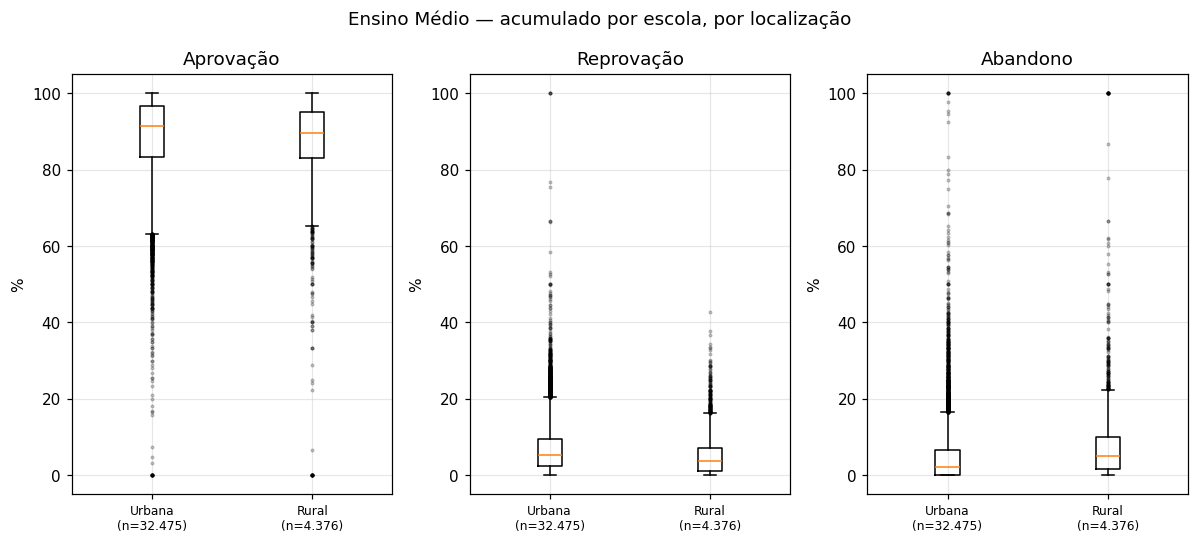

n     Q1  mediana     Q3  % zero  % outliers
LOCALIZACAO taxa                                                        
Urbana      Aprovação   32475  83.33    91.45  96.74    0.04        1.61
            Reprovação  32475   2.36     5.22   9.60    6.63        2.80
            Abandono    32475   0.12     2.24   6.70   19.95        3.54
Rural       Aprovação    4376  83.11    89.69  95.00    0.34        2.63
            Reprovação   4376   1.14     3.67   7.17   17.00        3.79
            Abandono     4376   1.72     5.11  10.00   11.04        3.70

In [21]:
boxplot_por(acc, COL_LOC, f"{NOME_ETAPA[ETAPA]} — acumulado por escola, por localização",
            f"{ETAPA}_acumulado_localizacao.png", ordem=ORDEM_LOC, largura=11)
resumos["localizacao"] = resumo_por(acc, COL_LOC, ordem=ORDEM_LOC)
resumos["localizacao"]

### 6.4 Combinações: rede × localização

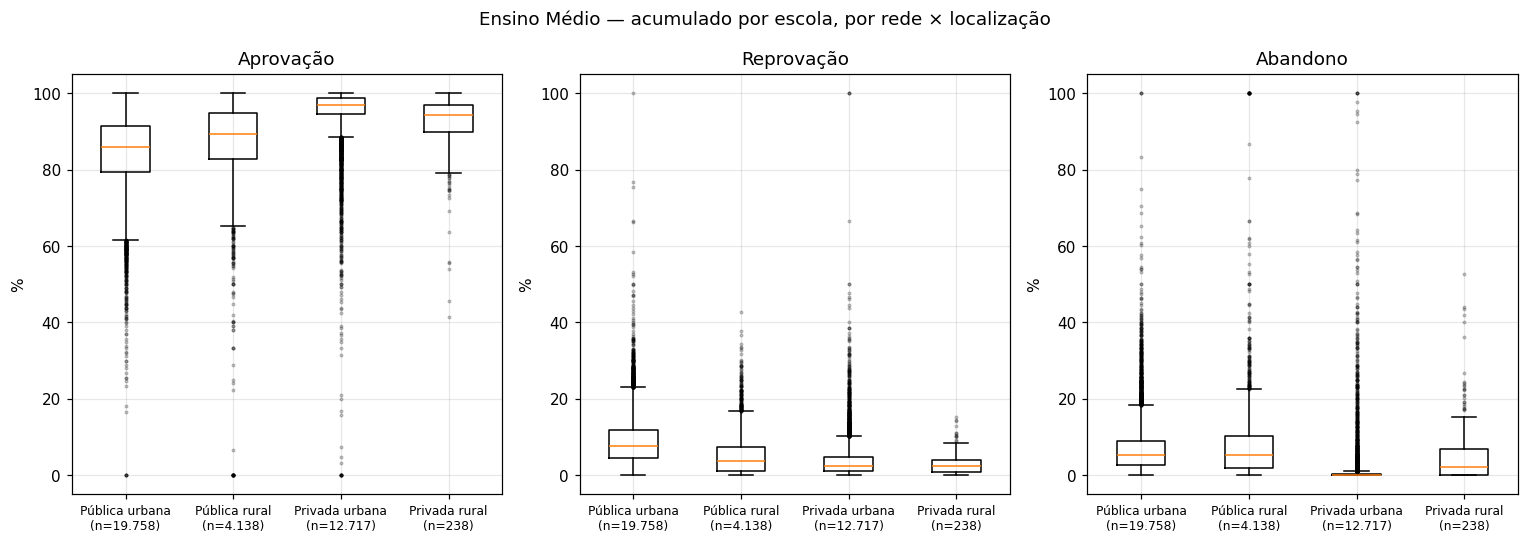

n     Q1  mediana     Q3  % zero  % outliers
grupo          taxa                                                        
Pública urbana Aprovação   19758  79.49    85.96  91.48    0.03        1.68
               Reprovação  19758   4.46     7.67  11.87    2.07        2.33
               Abandono    19758   2.57     5.35   8.92    3.28        3.49
Pública rural  Aprovação    4138  82.91    89.41  94.76    0.36        2.59
               Reprovação   4138   1.17     3.82   7.43   16.99        3.60
               Abandono     4138   1.89     5.32  10.14   10.54        3.53
Privada urbana Aprovação   12717  94.59    97.02  98.65    0.07        6.76
               Reprovação  12717   1.01     2.53   4.66   13.71        5.10
               Abandono    12717   0.00     0.06   0.41   45.84       12.79
Privada rural  Aprovação     238  89.81    94.28  97.05    0.00       10.08
               Reprovação    238   0.75     2.28   3.98   17.23        5.04
               Abandono      238   0.11     2.27   6.83   19.75       10.50

In [22]:
boxplot_por(acc, "grupo", f"{NOME_ETAPA[ETAPA]} — acumulado por escola, por rede × localização",
            f"{ETAPA}_acumulado_combinacoes.png", ordem=ORDEM_GRUPO, largura=14)
resumos["combinacoes"] = resumo_por(acc, "grupo", ordem=ORDEM_GRUPO)
resumos["combinacoes"]

### 6.5 Por UF

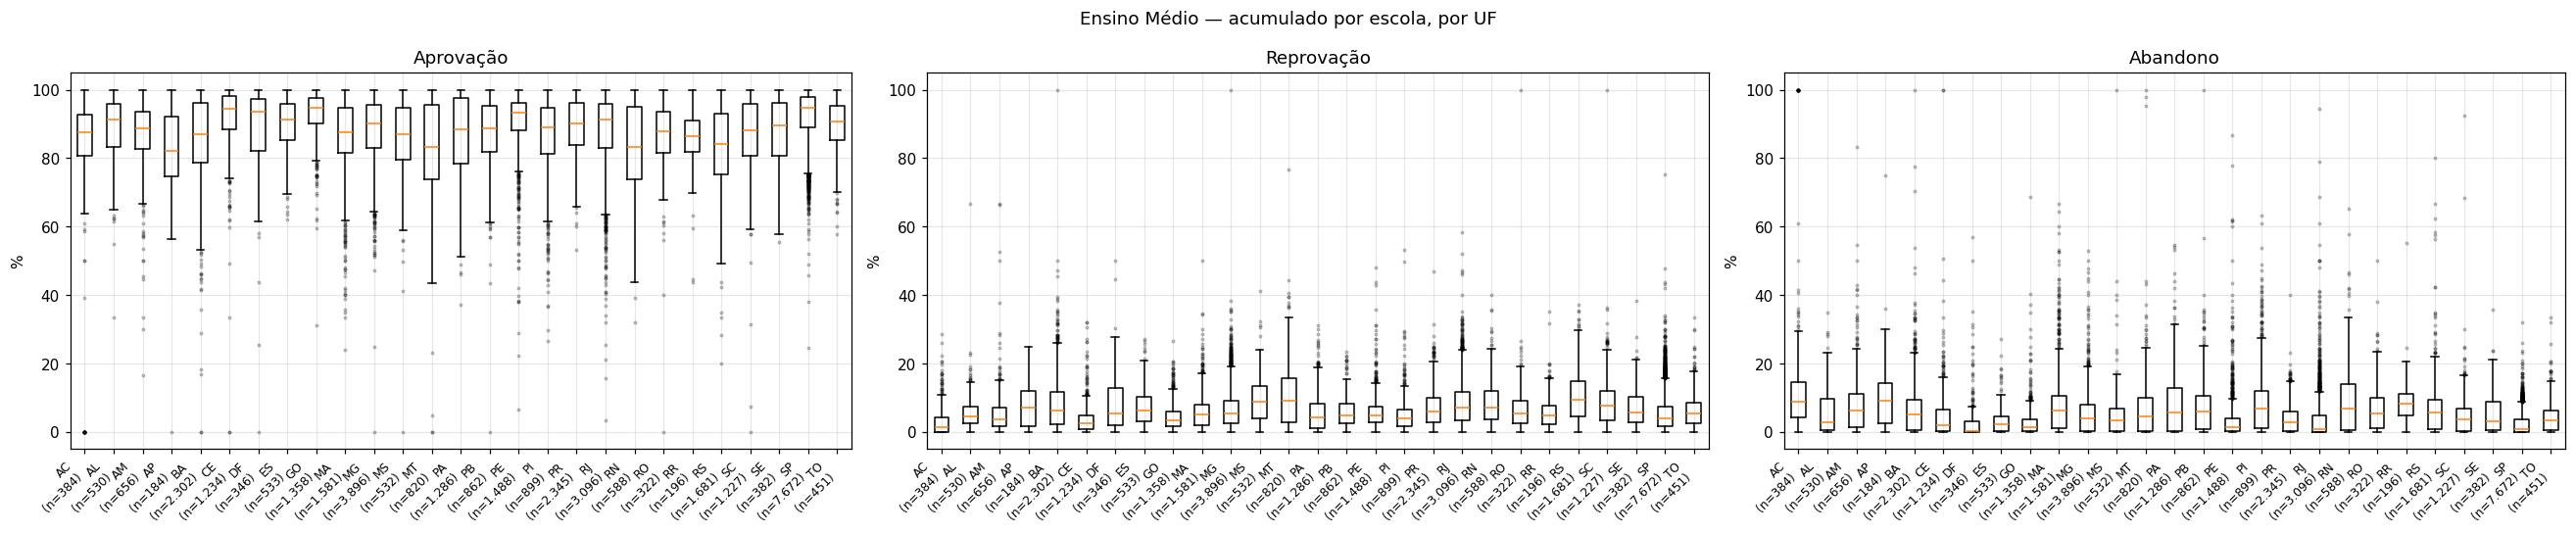

n     Q1  mediana     Q3  % zero  % outliers
UF taxa                                                       
AC Aprovação    384  80.65    87.60  92.62    4.17        5.73
   Reprovação   384   0.00     1.43   4.33   32.55        8.07
   Abandono     384   4.36     8.94  14.52    8.07        7.55
AL Aprovação    530  83.15    91.29  95.91    0.00        1.13
   Reprovação   530   2.45     4.57   7.43    7.36        2.64
...             ...    ...      ...    ...     ...         ...
SP Reprovação  7672   1.75     3.85   7.37    5.41        4.22
   Abandono    7672   0.00     0.68   3.56   31.24        2.85
TO Aprovação    451  85.17    90.65  95.22    0.00        2.22
   Reprovação   451   2.51     5.34   8.57    7.32        3.77
   Abandono     451   0.53     3.39   6.30   16.85        3.33

[81 rows x 6 columns]

In [23]:
boxplot_por(acc, COL_UF, f"{NOME_ETAPA[ETAPA]} — acumulado por escola, por UF",
            f"{ETAPA}_acumulado_uf.png", ordem=None, largura=24)
resumos["uf"] = resumo_por(acc, COL_UF, ordem=None)
resumos["uf"]

**Pontos para observar**
- **Federal × estadual:** se as caixas forem muito diferentes, juntar tudo como "pública" esconde a diferença.
- **% zero alto:** onde a caixa "some" no zero, a mediana sozinha diz pouco. Vale olhar o % de zeros.
- **Combinações com n pequeno** (por exemplo, privada rural): pesam pouco e podem oscilar muito.

## 7. Sensibilidade

Duas perguntas:
1. **Escola-ano ou acumulado?** Se as duas versões contam a mesma história, a escolha pesa pouco.
2. **Escolas pequenas mudam o quadro?** Mesma figura só com escolas de matrícula média anual ≥ `MIN_MAT`.

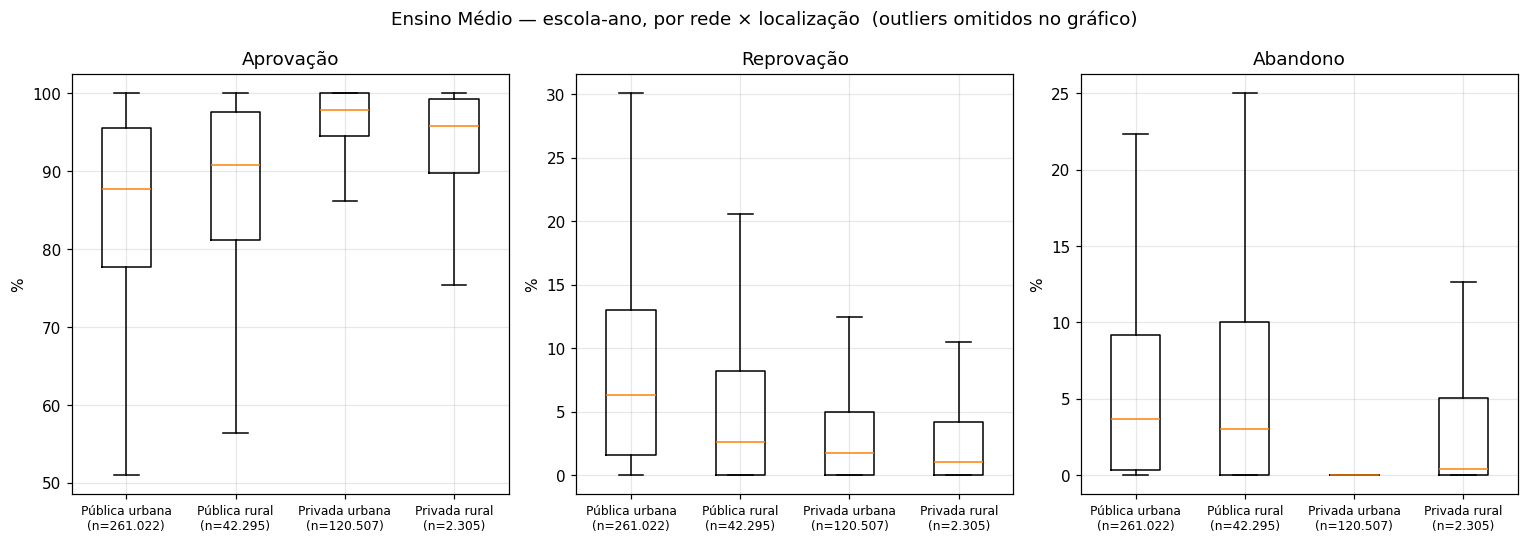

In [24]:
boxplot_por(esc_ano, "grupo", f"{NOME_ETAPA[ETAPA]} — escola-ano, por rede × localização",
            f"{ETAPA}_escola_ano_combinacoes.png", ordem=ORDEM_GRUPO, fliers=False)
resumos["combinacoes_escola_ano"] = resumo_por(esc_ano, "grupo", ordem=ORDEM_GRUPO)

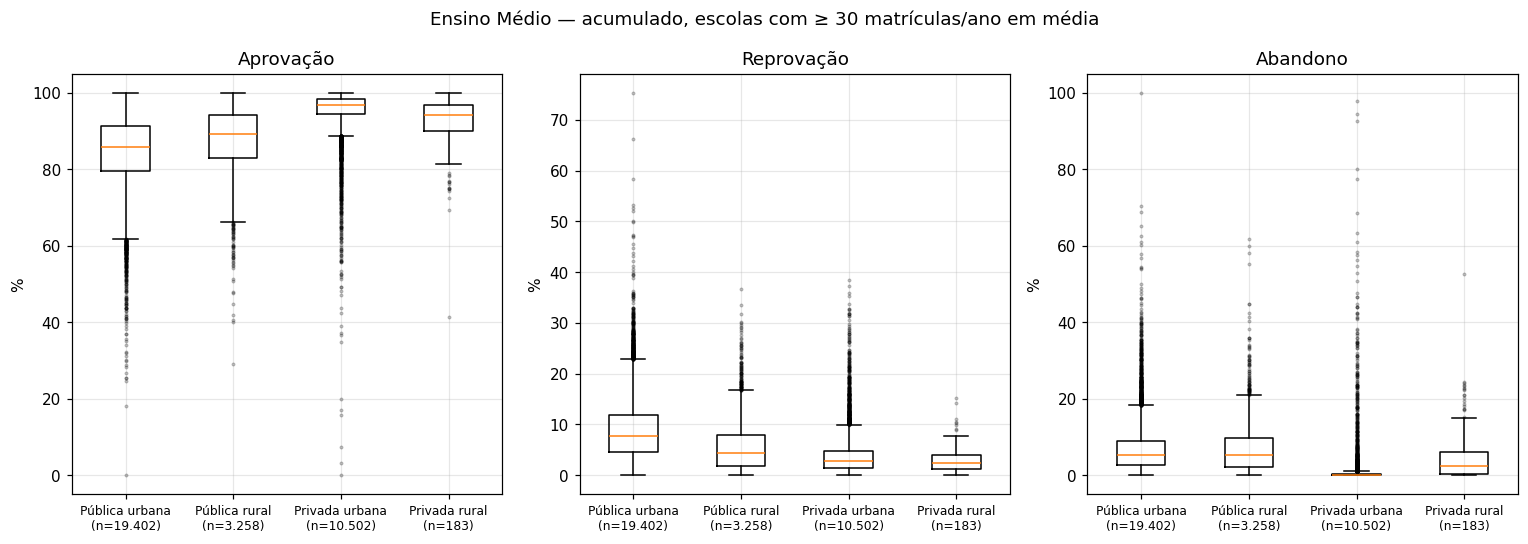

In [25]:
grandes = acc[acc["mat_media_anual"] >= MIN_MAT]
boxplot_por(grandes, "grupo",
            f"{NOME_ETAPA[ETAPA]} — acumulado, escolas com ≥ {MIN_MAT} matrículas/ano em média",
            f"{ETAPA}_acumulado_combinacoes_min{MIN_MAT}.png", ordem=ORDEM_GRUPO)
resumos[f"combinacoes_min{MIN_MAT}"] = resumo_por(grandes, "grupo", ordem=ORDEM_GRUPO)

In [26]:
# medianas lado a lado nas três versões
comparacao = pd.concat({
    "acumulado": resumos["combinacoes"]["mediana"],
    "escola-ano": resumos["combinacoes_escola_ano"]["mediana"],
    f"acumulado, ≥{MIN_MAT}": resumos[f"combinacoes_min{MIN_MAT}"]["mediana"],
}, axis=1)
comparacao

acumulado  escola-ano  acumulado, ≥30
grupo          taxa                                             
Pública urbana Aprovação       85.96       87.67           85.89
               Reprovação       7.67        6.29            7.71
               Abandono         5.35        3.68            5.38
Pública rural  Aprovação       89.41       90.80           89.13
               Reprovação       3.82        2.60            4.36
               Abandono         5.32        3.05            5.34
Privada urbana Aprovação       97.02       97.87           96.84
               Reprovação       2.53        1.79            2.77
               Abandono         0.06        0.00            0.09
Privada rural  Aprovação       94.28       95.81           94.21
               Reprovação       2.28        1.06            2.44
               Abandono         2.27        0.43            2.43

## 8. Exportação

Salva todas as tabelas de resumo num único CSV (separador `;`, decimal `,`, para abrir direto no Excel). As figuras já foram salvas em `saida_exploracao/figuras/`.

In [27]:
saida = pd.concat(
    {nome: t.reset_index().rename(columns={t.index.names[0]: "grupo"}) for nome, t in resumos.items()},
    names=["recorte"]).reset_index(level=0)
arquivo = PASTA_SAIDA / f"resumo_boxplots_{ETAPA}.csv"
saida.to_csv(arquivo, index=False, sep=";", decimal=",", encoding="utf-8-sig")
print("Salvo em", arquivo)
saida.head()

Salvo em saida_exploracao\resumo_boxplots_EM.csv


,recorte,grupo,taxa,n,Q1,mediana,Q3,% zero,% outliers
0,regiao,Norte,Aprovação,3479,80.70,88.28,95.56,0.52,1.64
1,regiao,Norte,Reprovação,3479,1.33,4.21,8.12,13.16,2.44
2,regiao,Norte,Abandono,3479,0.81,6.00,11.66,12.50,2.39
3,regiao,Nordeste,Aprovação,9866,82.08,90.13,96.13,0.05,2.04
4,regiao,Nordeste,Reprovação,9866,2.05,4.72,8.33,10.64,3.59
